# Task 1: Local Search & Propositional Logic (N-Queens Problem)
**Course:** Introduction to Artificial Intelligence (503043)  
**Institution:** Faculty of Information Technology, Ton Duc Thang University (TDTU)  
**Author:** Student Group  

---

## Table of Contents
1. **Propositional Logic Formulation & CNF Clause Generation (Req 1)**
2. **Solving with Glucose3 SAT Solver (PySAT) for $N \ge 4$ (Req 2)**
3. **Min-Conflicts Local Search & Proposed Variable Selection Heuristics (Req 3)**
4. **Performance Benchmark & Comparative Evaluation**

### 1. Propositional Logic Formulation & CNF Clause Generation (Req 1 - 1.0 pt)

- **Boolean Propositional Variables:** Let $X_{r, c} \in \{True, False\}$ for $0 \le r, c < N$, representing whether a queen is placed at square $(r, c)$.
- **DIMACS Integer Encoding:** Variable indices are mapped to positive integers:
  $$\text{var\_id}(r, c) = r \cdot N + c + 1 \in [1, N^2]$$
- **Constraint Groups:**
  1. **Row Constraints (Exactly-One):**
     - At-Least-One (ALO): $\bigvee_{c=0}^{N-1} X_{r, c}$
     - At-Most-One (AMO): $\bigwedge_{0 \le c_1 < c_2 < N} (\neg X_{r, c_1} \lor \neg X_{r, c_2})$
  2. **Column Constraints (Exactly-One):**
     - At-Least-One (ALO): $\bigvee_{r=0}^{N-1} X_{r, c}$
     - At-Most-One (AMO): $\bigwedge_{0 \le r_1 < r_2 < N} (\neg X_{r_1, c} \lor \neg X_{r_2, c})$
  3. **Main Diagonal Constraints (AMO):** At most one queen on each diagonal $r - c = k$ for $-(N - 1) \le k \le N - 1$.
  4. **Anti Diagonal Constraints (AMO):** At most one queen on each diagonal $r + c = k$ for $0 \le k \le 2N - 2$.
- **Theoretical Clause Count Formula:**
  $$\text{Total Clauses} = 2N + N^2(N - 1) + \frac{N(N - 1)(2N - 1)}{3}$$

In [ ]:
import sys
import os

# Add parent source directory to sys.path
source_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if source_dir not in sys.path:
    sys.path.insert(0, source_dir)

from task1_nqueens.core.problem import NQueensProblem
from task1_nqueens.core.constraints import ConstraintGenerator

print("=== VERIFYING CNF CONSTRAINT GENERATOR INTEGRITY ===")
for test_n in [4, 6, 8]:
    prob = NQueensProblem(test_n)
    gen = ConstraintGenerator(prob)
    clauses = gen.generate_all_cnf()
    stats = gen.get_clause_statistics()
    theo = gen.get_theoretical_clause_count()
    print(f"[N = {test_n:2d}] Variables: {stats['variables']:3d} | Generated: {len(clauses):5d} | Theoretical: {theo:5d} | Exact Match: {len(clauses) == theo}")
    print(f"        Breakdown: Row ALO={stats['row_alo']}, Row AMO={stats['row_amo']}, Col ALO={stats['col_alo']}, Col AMO={stats['col_amo']}, Diag AMO={stats['diagonal_amo']}")


=== VERIFYING CNF CONSTRAINT GENERATOR INTEGRITY ===
[N =  4] Variables:  16 | Generated:    84 | Theoretical:    84 | Exact Match: True
        Breakdown: Row ALO=4, Row AMO=24, Col ALO=4, Col AMO=24, Diag AMO=28
[N =  6] Variables:  36 | Generated:   302 | Theoretical:   302 | Exact Match: True
        Breakdown: Row ALO=6, Row AMO=90, Col ALO=6, Col AMO=90, Diag AMO=110
[N =  8] Variables:  64 | Generated:   744 | Theoretical:   744 | Exact Match: True
        Breakdown: Row ALO=8, Row AMO=224, Col ALO=8, Col AMO=224, Diag AMO=280


c:\Users\Nhi\OneDrive\Documents\AI_final_project\source\task1_nqueens\core\constraints.py:70: SyntaxWarning: "\)" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\)"? A raw string is also an option.
  - Main diagonals (\): r - c = k for -(N - 1) <= k <= N - 1


### 2. Solving with Glucose3 SAT Solver (PySAT) for $N \ge 4$ (Req 2 - 1.0 pt)

We evaluate the Glucose3 solver from `pysat.solvers` across increasing values of $N \ge 4$ ($N = 4, 8, 12, 16, 20, 24, 28, 32$), recording clause counts and execution time.

In [ ]:
from task1_nqueens.solvers.sat_solver import Glucose3SATSolver

sat_solver = Glucose3SATSolver()
sat_results = []
test_sizes_sat = [4, 8, 12, 16, 20, 24, 28, 32]

print("=== GLUCOSE3 SAT SOLVER EXPERIMENT RESULTS (PySAT) ===")
print(f"{'N':>3} | {'Vars (N^2)':>10} | {'CNF Clauses':>12} | {'Time (sec)':>14} | {'Sample Solution (col->row)':<28}")
print("-" * 80)

for test_n in test_sizes_sat:
    res = sat_solver.solve(test_n)
    sat_results.append(res)
    sol_str = str(res.solution[:6]) + "..." if len(res.solution) > 6 else str(res.solution)
    print(f"{test_n:3d} | {test_n**2:10d} | {res.num_clauses:12d} | {res.execution_time:14.6f} | {sol_str:<28}")

# Display ASCII chessboard solution for N = 8
print("\nVisualization of N = 8 solution produced by Glucose3 SAT Solver:")
prob_8 = NQueensProblem(8)
res_8 = sat_solver.solve(8)
prob_8.display(res_8.solution)


=== GLUCOSE3 SAT SOLVER EXPERIMENT RESULTS (PySAT) ===
  N | Vars (N^2) |  CNF Clauses |     Time (sec) | Sample Solution (col->row)  
--------------------------------------------------------------------------------
  4 |         16 |           84 |       0.000077 | [1, 3, 0, 2]                
  8 |         64 |          744 |       0.000251 | [7, 1, 3, 0, 6, 4]...       
 12 |        144 |         2620 |       0.000427 | [11, 3, 10, 0, 9, 5]...     
 16 |        256 |         6352 |       0.026076 | [15, 12, 14, 3, 13, 6]...   
 20 |        400 |        12580 |       0.003171 | [19, 10, 6, 17, 14, 16]...  


 24 |        576 |        21944 |       0.125522 | [9, 20, 10, 19, 6, 23]...   


 28 |        784 |        35084 |       0.007520 | [10, 27, 6, 26, 21, 19]...  
 32 |       1024 |        52640 |       0.007031 | [12, 10, 8, 27, 25, 22]...  

Visualization of N = 8 solution produced by Glucose3 SAT Solver:

--- N-Queens Board (N = 8) ---
Row  0 | .  .  .  Q  .  .  .  . |
Row  1 | .  Q  .  .  .  .  .  . |
Row  2 | .  .  .  .  .  .  Q  . |
Row  3 | .  .  Q  .  .  .  .  . |
Row  4 | .  .  .  .  .  Q  .  . |
Row  5 | .  .  .  .  .  .  .  Q |
Row  6 | .  .  .  .  Q  .  .  . |
Row  7 | Q  .  .  .  .  .  .  . |
       ------------------------
 Col     0  1  2  3  4  5  6  7



### 3. Min-Conflicts Local Search & Proposed Variable Selection Heuristics (Req 3 - 1.0 pt)

- **Complete-State Formulation (Lecture 06):** Each column has exactly one queen (`state[col] = row`).
- **Standard Baseline (Lecture 08 - Slide 30):** Random selection among all currently conflicted variables.
- **Proposed Heuristic 1 (Max-Conflict):** Inspired by the Degree Heuristic (Lecture 08 - Slide 26), picks the queen currently involved in the largest number of attacks.
- **Proposed Heuristic 2 (Hybrid-Tabu):** Combines random walk exploration (Lecture 09 - Slide 48) with short-term tabu list (Lecture 08 - Slide 31) to escape local plateaux.

In [ ]:
from task1_nqueens.solvers.min_conflicts import MinConflictsSolver
from task1_nqueens.solvers.heuristics import RandomSelector, MaxConflictSelector, HybridTabuSelector

solver_random = MinConflictsSolver(heuristic=RandomSelector())
solver_max_conf = MinConflictsSolver(heuristic=MaxConflictSelector())
solver_hybrid = MinConflictsSolver(heuristic=HybridTabuSelector())

print("=== SINGLE-RUN COMPARISON: STEPS AND EXECUTION TIME ===")
for test_n in [8, 16, 32, 64]:
    res_rnd = solver_random.solve(test_n)
    res_max = solver_max_conf.solve(test_n)
    res_hyb = solver_hybrid.solve(test_n)
    print(f"\n[N = {test_n}]:")
    print(f"  - Standard (Random)    : Steps={res_rnd.steps_taken:5d} | Time={res_rnd.execution_time:.5f}s | Solved={res_rnd.is_solved}")
    print(f"  - Heuristic (Max-Conf) : Steps={res_max.steps_taken:5d} | Time={res_max.execution_time:.5f}s | Solved={res_max.is_solved}")
    print(f"  - Heuristic (Hybrid)   : Steps={res_hyb.steps_taken:5d} | Time={res_hyb.execution_time:.5f}s | Solved={res_hyb.is_solved}")


=== SINGLE-RUN COMPARISON: STEPS AND EXECUTION TIME ===

[N = 8]:
  - Standard (Random)    : Steps=   80 | Time=0.00090s | Solved=True
  - Heuristic (Max-Conf) : Steps=   56 | Time=0.00090s | Solved=True
  - Heuristic (Hybrid)   : Steps=   13 | Time=0.00027s | Solved=True

[N = 16]:
  - Standard (Random)    : Steps=   19 | Time=0.00040s | Solved=True
  - Heuristic (Max-Conf) : Steps=   51 | Time=0.00120s | Solved=True
  - Heuristic (Hybrid)   : Steps=   61 | Time=0.00134s | Solved=True

[N = 32]:
  - Standard (Random)    : Steps=  123 | Time=0.00309s | Solved=True
  - Heuristic (Max-Conf) : Steps=   88 | Time=0.00280s | Solved=True
  - Heuristic (Hybrid)   : Steps=   32 | Time=0.00155s | Solved=True

[N = 64]:
  - Standard (Random)    : Steps=   93 | Time=0.00720s | Solved=True
  - Heuristic (Max-Conf) : Steps=   75 | Time=0.00406s | Solved=True
  - Heuristic (Hybrid)   : Steps=   66 | Time=0.00331s | Solved=True


### 4. Comprehensive Benchmark & Comparative Evaluation

We execute multi-trial benchmarks to collect reliable average metrics and plot comparison curves.

In [ ]:
from task1_nqueens.experiments.benchmark import BenchmarkRunner

runner = BenchmarkRunner(
    sat_sizes=[4, 8, 12, 16, 20, 24, 28, 32],
    mc_sizes=[8, 16, 32, 64, 100],
    num_trials=3
)

runner.run_sat_experiments()
runner.run_min_conflicts_experiments()
chart_path = runner.plot_comparisons("benchmark_task1.png")
print("\n" + runner.export_to_table())


=== STARTING GLUCOSE3 SAT SOLVER EXPERIMENTS (PySAT) ===
-> [SAT] N= 4 | Clauses:     84 | Avg Time: 0.000022s | Solved: True
-> [SAT] N= 8 | Clauses:    744 | Avg Time: 0.000217s | Solved: True
-> [SAT] N=12 | Clauses:   2620 | Avg Time: 0.000476s | Solved: True
-> [SAT] N=16 | Clauses:   6352 | Avg Time: 0.029638s | Solved: True


-> [SAT] N=20 | Clauses:  12580 | Avg Time: 0.003479s | Solved: True


-> [SAT] N=24 | Clauses:  21944 | Avg Time: 0.131036s | Solved: True
-> [SAT] N=28 | Clauses:  35084 | Avg Time: 0.007248s | Solved: True


-> [SAT] N=32 | Clauses:  52640 | Avg Time: 0.008204s | Solved: True

=== STARTING MIN-CONFLICTS HEURISTIC COMPARISONS ===
-> [MC] N=  8 | Standard (Random)                   | Steps:     52.0 | Time: 0.00067s | Success: 100%
-> [MC] N=  8 | Proposed Heuristic 1 (Max-Conflict) | Steps:     33.7 | Time: 0.00038s | Success: 100%
-> [MC] N=  8 | Proposed Heuristic 2 (Hybrid-Tabu)  | Steps:    526.3 | Time: 0.00600s | Success: 100%
-> [MC] N= 16 | Standard (Random)                   | Steps:     49.0 | Time: 0.00059s | Success: 100%
-> [MC] N= 16 | Proposed Heuristic 1 (Max-Conflict) | Steps:    229.7 | Time: 0.00374s | Success: 100%
-> [MC] N= 16 | Proposed Heuristic 2 (Hybrid-Tabu)  | Steps:     56.3 | Time: 0.00101s | Success: 100%
-> [MC] N= 32 | Standard (Random)                   | Steps:     93.7 | Time: 0.00186s | Success: 100%
-> [MC] N= 32 | Proposed Heuristic 1 (Max-Conflict) | Steps:     67.0 | Time: 0.00195s | Success: 100%
-> [MC] N= 32 | Proposed Heuristic 2 (Hybrid-Tabu)  |


[Visual] Benchmark comparison plot saved to: c:\Users\Nhi\OneDrive\Documents\AI_final_project\source\task1_nqueens\benchmark_task1.png

### Table 1: Glucose3 SAT Solver Performance (PySAT) - Req 2

| N | Variables ($N^2$) | Generated Clauses | Theoretical Clauses | Avg Runtime (s) | Status |
|:---:|:---:|:---:|:---:|:---:|:---:|
| 4 | 16 | 84 | 84 | 0.000022 | SAT |
| 8 | 64 | 744 | 744 | 0.000217 | SAT |
| 12 | 144 | 2620 | 2620 | 0.000476 | SAT |
| 16 | 256 | 6352 | 6352 | 0.029638 | SAT |
| 20 | 400 | 12580 | 12580 | 0.003479 | SAT |
| 24 | 576 | 21944 | 21944 | 0.131036 | SAT |
| 28 | 784 | 35084 | 35084 | 0.007248 | SAT |
| 32 | 1024 | 52640 | 52640 | 0.008204 | SAT |

### Table 2: Min-Conflicts Baseline vs Proposed Heuristics - Req 3

| N | Variable Selection Heuristic | Avg Steps | Avg Runtime (s) | Success Rate |
|:---:|:---|:---:|:---:|:---:|
| 8 | Standard (Random) | 52.0 | 0.000673 | 100% |
| 8 | Proposed Heuristic 1 (Max-Conflict) | 33.67 | 0.000385 | 100% |
| 8 | Proposed

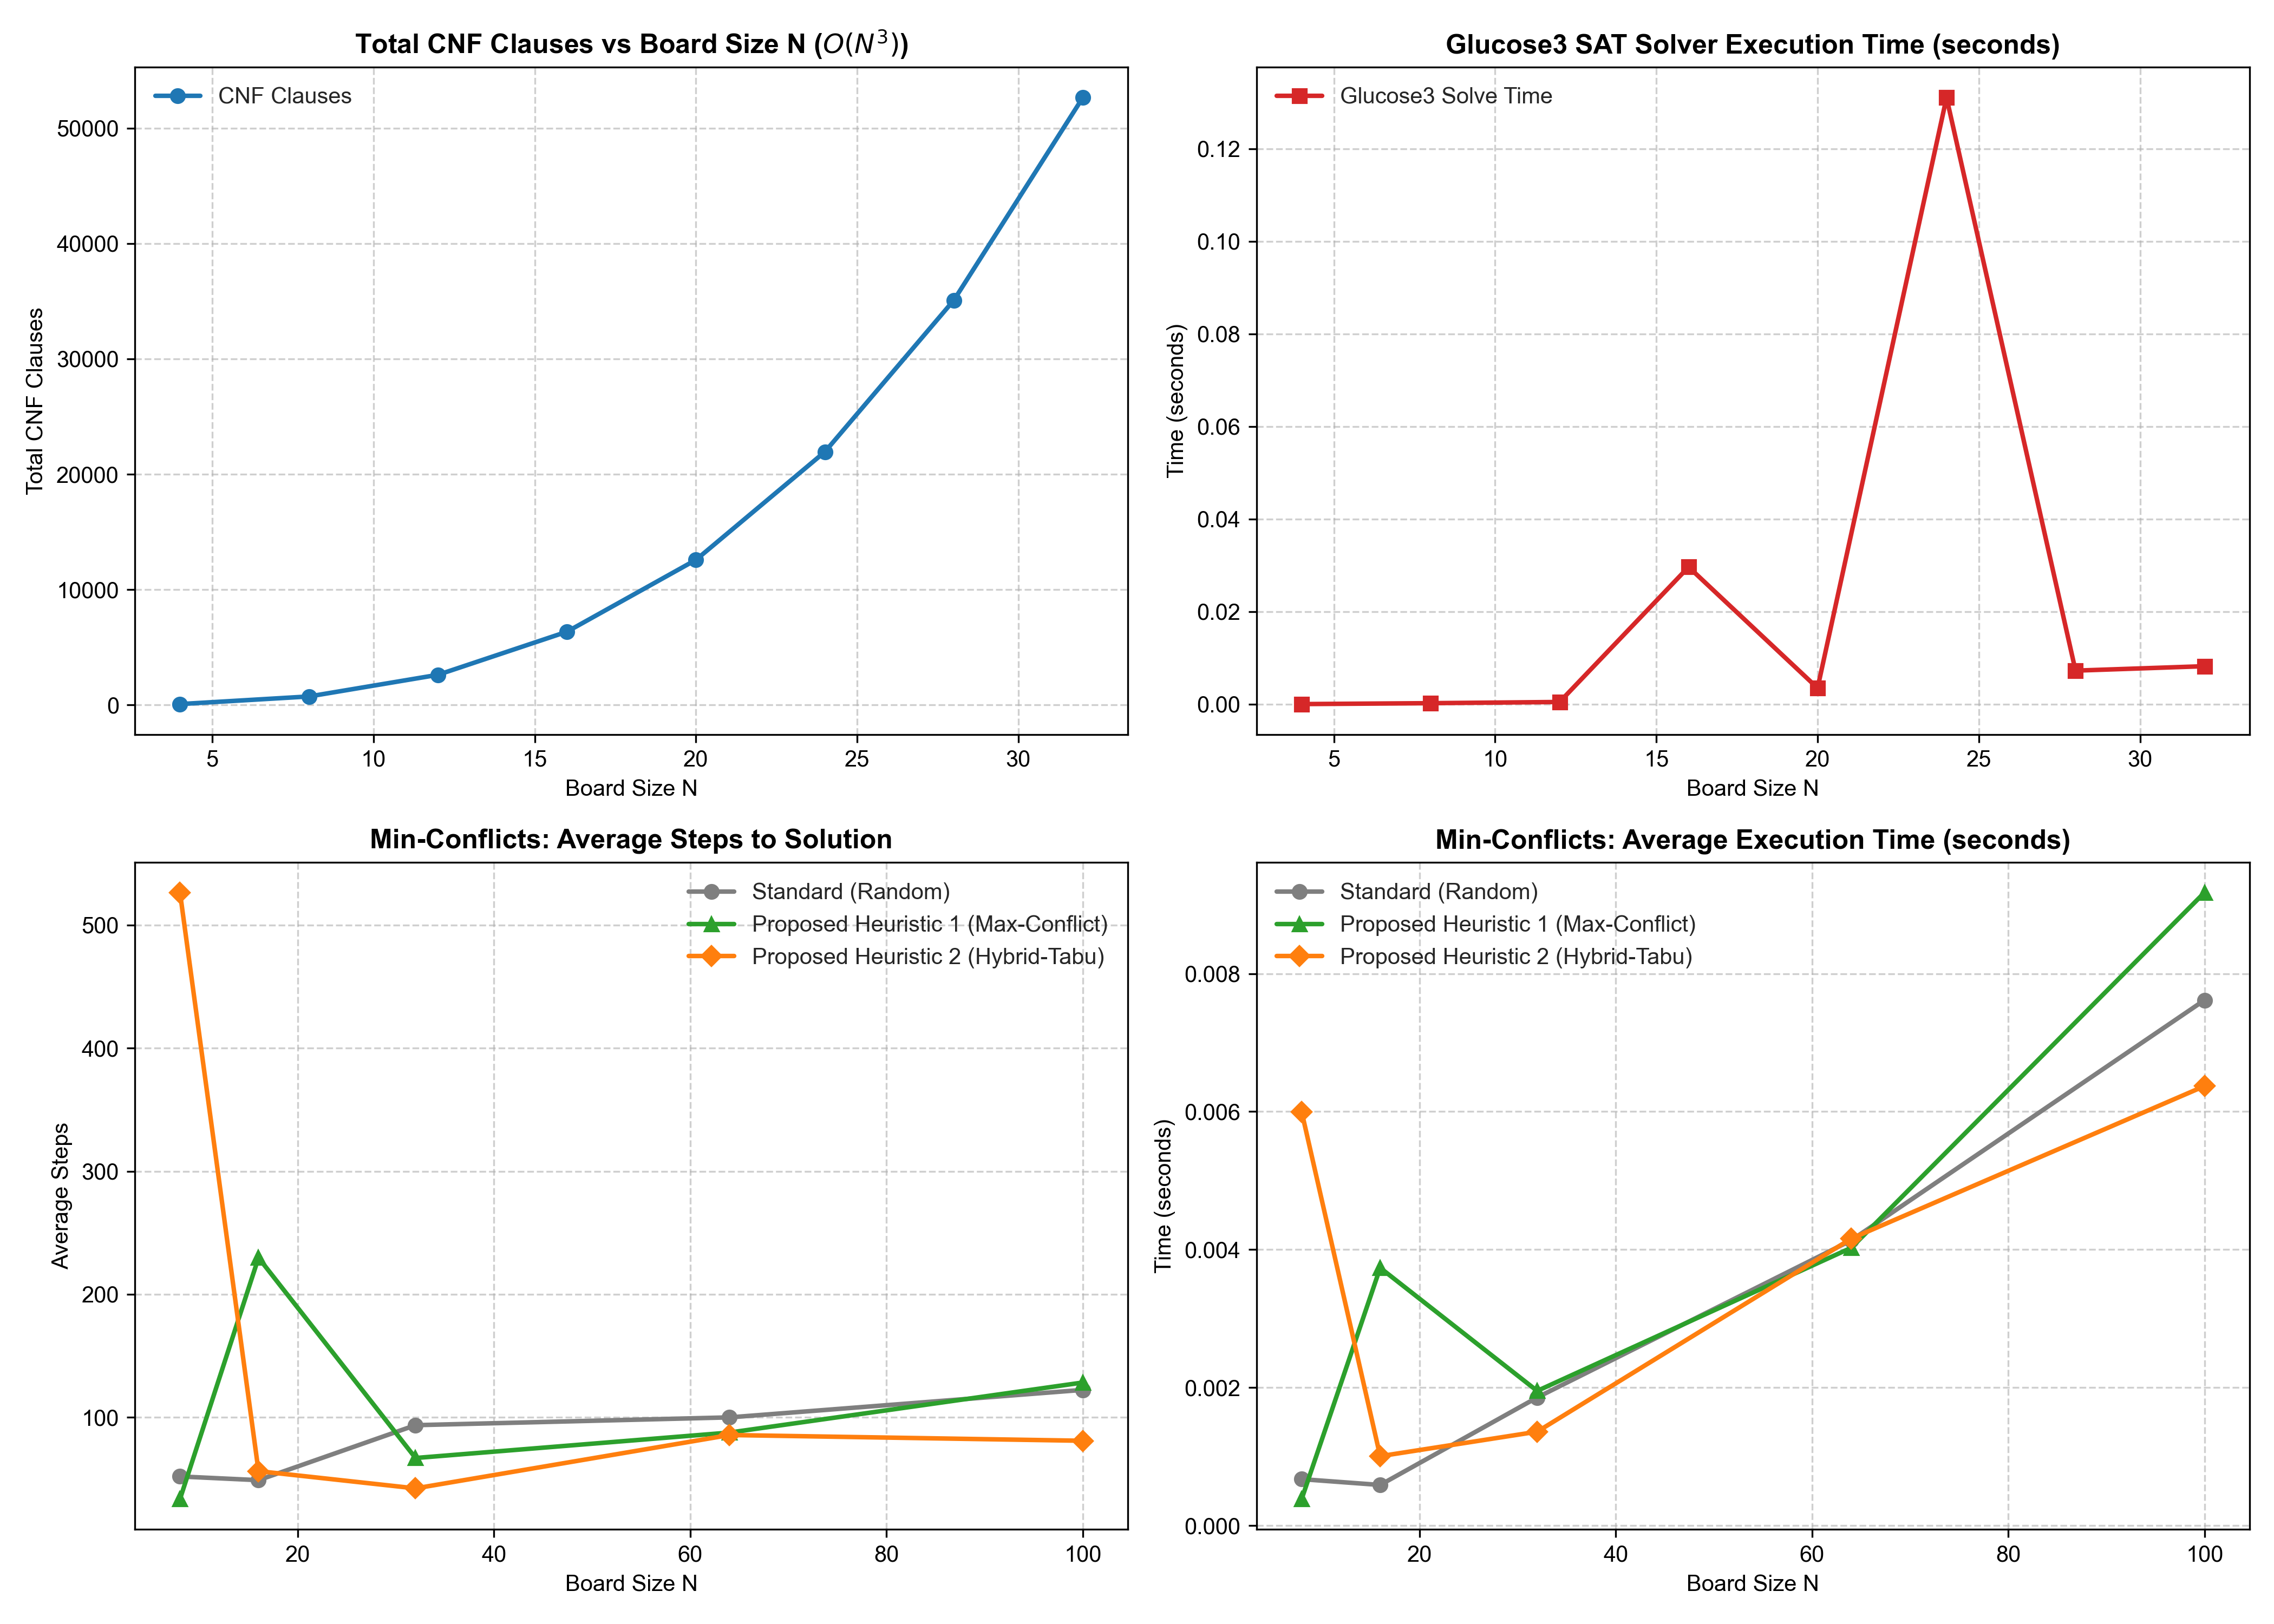

In [ ]:
# Display benchmark figure directly in notebook
from IPython.display import Image, display
if os.path.exists("benchmark_task1.png"):
    display(Image(filename="benchmark_task1.png"))
